# E-commerce Product Analytics — User Behavior

## 1. Business Questions

This analysis looks at user behavior beyond the purchase funnel and answers the following questions:

- How active are users: how many events, active days and event types does a user have?
- Do sessions in the dataset look like real visits, so that user paths inside sessions can be analyzed?
- Do users who trigger any `feature_click` event purchase more often than users who do not?
- Is this difference specific to feature usage, or does it also appear for other actions and for users with similar activity?

## 2. Metrics and Definitions

- **Activity** — the number of events of a user in the observed period, without `session_end` (a technical event). **Active days** — the number of distinct days with at least one event. **Active period** — days from the first to the last event of the user.
- **Session** — events with the same `session_id`. In a typical product, a session is one visit that ends with `session_end`.
- **Behavioral cohort** — a group of users defined by an action they performed (here: `feature_click`), as opposed to an acquisition cohort defined by the start date. `feature_click` covers 10 features (`feature_name`, for example `profile`, `search` or `checkout`). **Feature users** are users who triggered any `feature_click` event, across all `feature_name` values; the analysis does not evaluate any specific feature.
- **Funnel conversion** — purchase through the sequential funnel without a time limit, as in `04_funnel.ipynb` (Section 4): website visit → product view → add to cart → checkout start → purchase, each step after the previous one. Used only to reproduce the draft method (Section 6, Step 1).
- **Fixed windows** — the action and early activity are measured in the first 30 days after the first website visit, and the outcome is **any purchase** (`checkout_complete`) in days 31–60 after the first visit. So the action is measured before the outcome, and all users have the same periods.

Cohort definitions follow Amplitude's cohort analysis guide (see References).

## 3. Data

The analysis uses `events_clean` — the `events` table without the anomalous June–August 2023 sessions found in `01_engagement.ipynb` (Section 4). As in the other notebooks, only events before the start of the partially covered last day (18 August 2025) are used.

Key fields:

- `user_id` — user identifier
- `session_id` — session identifier
- `event_time` — event timestamp
- `event_name` — event type

Activity (Section 4) covers all 1,000 users. Behavioral cohorts (Section 6) cover users with at least one website visit: 972 users for the draft method, as in the funnel, and 969 users for the fixed windows — those whose first visit plus 60 days is before 18 August 2025, so that both windows are fully observed.

The behavioral cohort logic (the draft method, reproduced in Section 6, Step 1) and the session-level path analysis come from an earlier version of this analysis. Query results are stored in `data/results/05_user_behavior/` and re-created with `python scripts/export_results.py`.

### Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.grid': True,
    'grid.alpha': 0.3
})

RESULTS = "../data/results/05_user_behavior/"

## 4. User Activity

### Business Question

How many events, active days and event types does a user have, and how are events split by type?

### SQL

[01_activity.sql](../sql/05_user_behavior/01_activity.sql)

Activity per user:

```sql
SELECT
    user_id,
    COUNT(*) AS events,
    COUNT(DISTINCT CAST(event_time AS DATE)) AS active_days,
    COUNT(DISTINCT event_name) AS event_types,
    date_diff('day', CAST(MIN(event_time) AS DATE), CAST(MAX(event_time) AS DATE)) + 1 AS active_period_days
FROM events_observed
GROUP BY user_id
```

### Results

In [2]:
event_types = pd.read_csv(RESULTS + "event_types.csv")

event_types

,event_name,events,users,pct_of_events
0,app_open,4627,973,7.8
1,feature_click,4614,969,7.8
2,notification_click,4606,966,7.8
3,profile_view,4593,968,7.8
4,video_play,4581,963,7.8
5,add_to_cart,4574,973,7.7
6,content_share,4566,958,7.7
7,checkout_complete,4517,967,7.6
8,website_visit,4517,972,7.6
9,checkout_start,4501,961,7.6


In [3]:
pd.read_csv(RESULTS + "feature_click_by_feature.csv")

,feature_name,events,users
0,profile,484,373
1,help_center,479,374
2,search,478,369
3,video_player,473,367
4,notifications,470,354
5,checkout,459,360
6,messages,454,353
7,settings,443,353
8,feed,439,338
9,homepage,435,352


In [4]:
activity = pd.read_csv(RESULTS + "user_activity.csv")

activity.describe().round(1)

,events,active_days,event_types,active_period_days
count,1000.0,1000.0,1000.0,1000.0
mean,59.1,41.9,12.6,88.3
std,24.0,13.1,0.8,3.3
min,20.0,15.0,8.0,67.0
25%,38.0,31.0,12.0,87.0
50%,58.0,43.0,13.0,89.0
75%,80.0,53.0,13.0,91.0
max,100.0,69.0,13.0,92.0


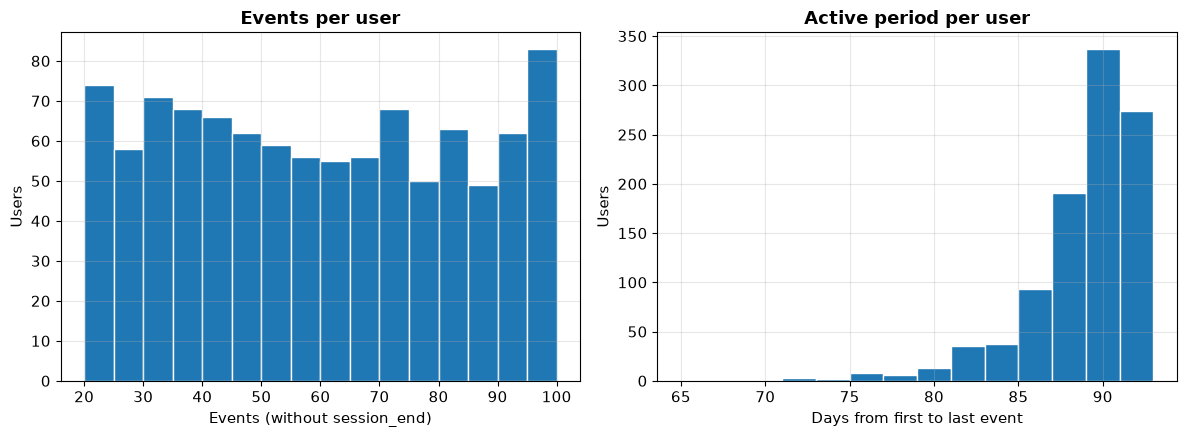

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(activity["events"], bins=range(20, 105, 5), color="tab:blue", edgecolor="white")
axes[0].set_title("Events per user")
axes[0].set_xlabel("Events (without session_end)")
axes[0].set_ylabel("Users")

axes[1].hist(activity["active_period_days"], bins=range(65, 95, 2), color="tab:blue", edgecolor="white")
axes[1].set_title("Active period per user")
axes[1].set_xlabel("Days from first to last event")
axes[1].set_ylabel("Users")

plt.tight_layout()
plt.show()

### Finding

The 13 event types have almost equal shares: each is 7.5–7.8% of all events, and each type is used by 945–975 of 1,000 users. A typical user performs all 13 event types (median 13). `feature_click` is split almost evenly across its 10 features: 435–484 events and 338–374 users per feature.

A user has 20 to 100 events (median 58), spread roughly evenly over this range, on 15 to 69 active days (median 43). The active period is very similar for all users: 67 to 92 days from the first to the last event (median 89).

Activity therefore varies little in its structure: every user is active for about three months, and event types appear with equal frequency. This is consistent with the synthetic nature of the data and is taken into account in Section 6: users with more events have more chances to complete any sequence of events.

## 5. Session Check

### Business Question

Do sessions look like real visits, so that user paths inside sessions can be analyzed?

An earlier version of this analysis analyzed what users do after checkout start within the same session. This requires sessions that look like visits: short, with `session_end` as the last event. Two checks test this.

### SQL

[02_session_check.sql](../sql/05_user_behavior/02_session_check.sql)

### Check 1. Session length

In [6]:
pd.read_csv(RESULTS + "session_summary.csv")

,sessions,min_events,median_events,p25_duration_days,median_duration_days,p75_duration_days,pct_longer_than_1_day
0,12341,2,5.0,43.0,62.0,75.3,99.6


### Check 2. Position of `session_end` in the session

In [7]:
pd.read_csv(RESULTS + "session_end_position.csv")

,session_end_position,sessions,pct
0,In the middle,6513,52.8
1,Last event,2944,23.9
2,First event,2884,23.4


### Check 3. The `duration_ms` field of `session_end`

In [8]:
pd.read_csv(RESULTS + "session_duration_ms.csv")

,sessions,sessions_with_duration_ms,min_duration_ms_minutes,median_duration_ms_minutes,max_duration_ms_minutes,median_timestamp_duration_days,event_types_with_duration_ms
0,12341,12341,0.5,15.2,30.0,62.0,13


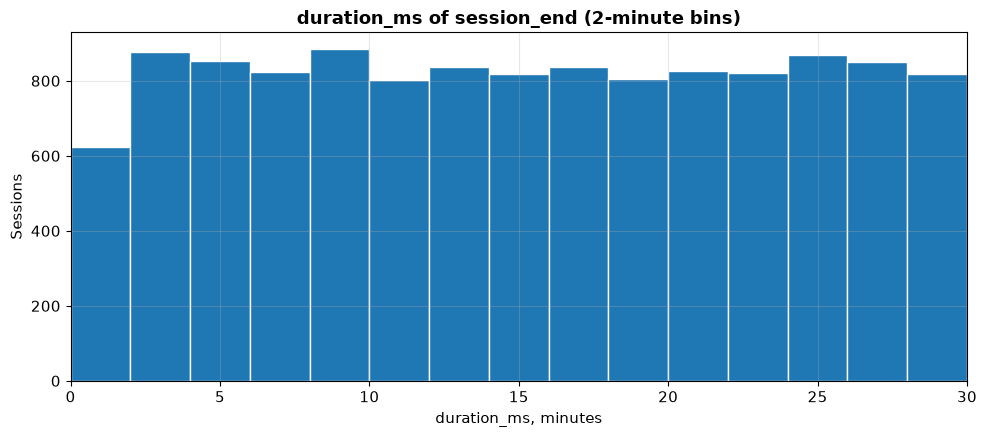

In [9]:
duration_bins = pd.read_csv(RESULTS + "session_duration_ms_distribution.csv")

plt.figure(figsize=(10, 4.5))
plt.bar(duration_bins["bin_start_minutes"], duration_bins["sessions"], width=2, align="edge",
        color="tab:blue", edgecolor="white")
plt.title("duration_ms of session_end (2-minute bins)")
plt.xlabel("duration_ms, minutes")
plt.ylabel("Sessions")
plt.xlim(0, 30)
plt.tight_layout()
plt.show()

### Finding

Sessions do not look like visits. Every one of the 12,341 sessions has at least two events, so the duration covers all sessions. The median session lasts 62 days from its first to its last event (interquartile range 43–75 days), and 99.6% of sessions last longer than one day. `session_end` is the last event of the session in only 23.9% of sessions — about as often as it is the first event (23.4%); in 52.8% of sessions it is in the middle.

The `duration_ms` field of `session_end` gives a very different session length: 0.5 to 30 minutes (median 15.2), compared with a median of 62 days between the first and the last event of the same sessions. The values are spread almost evenly over this range: 802–885 sessions in every 2-minute bin (624 in the first bin, which starts at 0.5 minutes). Such an even spread is consistent with values generated at random within a fixed range, although the data do not show how they were produced. The two sources cannot both describe the same visit. `duration_ms` is not described in the data dictionary and is filled for 13 of 14 event types, so its meaning is not confirmed, and 15 minutes is not taken as the true session length either. The contradiction between the two measures is another sign that sessions in this dataset are not reliable.

Therefore, a path analysis inside sessions is not done in this notebook: in this dataset, "the next event in the same session" is not the next action of a visit. The order of events at the user level was already checked in `04_funnel.ipynb` (Section 7): after checkout start, the next event is any event type with almost equal frequency.

## 6. Behavioral Cohorts: Feature Users vs Non-Feature Users

### Business Question

Do users who trigger any `feature_click` event (feature users) purchase more often than users who do not, and is this difference specific to feature usage?

### SQL

[03_behavioral_cohorts.sql](../sql/05_user_behavior/03_behavioral_cohorts.sql)

The analysis has three steps:

1. **The draft method.** A user is a feature user if they have a `feature_click` event (any `feature_name`) between the first website visit and the last funnel step they reached; the outcome is funnel conversion.
2. **Comparison with other actions.** The same comparison is repeated for all eight non-funnel event types, first with the draft method and then with fixed windows: the event in the first 30 days after the first visit, the outcome is any purchase in days 31–60.
3. **Comparison within activity groups.** Users are split into four equal groups (quartiles) by their number of events in the first 30 days, and feature users are compared with non-feature users within each group, with the same fixed windows.

For the fixed windows, a user is included only if both 30-day windows are fully observed: first visit + 60 days must be before 18 August 2025, the start of the partially covered last day (969 users). This is the same conservative rule as for the conversion windows in `04_funnel.ipynb`.

The draft method:

```sql
CASE WHEN EXISTS (
    SELECT 1 FROM events_observed e
    WHERE e.user_id = f.user_id
      AND e.event_name = 'feature_click'
      AND e.event_time > f.first_visit_time
      AND e.event_time < f.last_step_time
) THEN 'Feature users' ELSE 'Non-feature users' END AS cohort
```

### Step 1. The draft method

In [10]:
draft = pd.read_csv(RESULTS + "feature_cohort_draft.csv")

draft

,cohort,users,purchase_users,conversion_pct,users_only_visit,median_days_visit_to_last_step
0,Feature users,698,391,56.0,0,49.0
1,Non-feature users,274,48,17.5,106,10.0


Feature users complete the funnel more often: 56.0% vs 17.5%, a difference of 38.5 percentage points. The earlier draft interpreted a similar difference as a strong association between feature usage and conversion.

However, the method itself favors users who reach later funnel steps. The feature click is counted only between the first visit and the last step reached, so the further a user gets in the funnel, the longer this interval and the more chances to have any event in it. Users who did not get past the first visit have an empty interval and are always non-feature users: these are 106 of the 274 non-feature users. The median interval is 49 days for feature users and 10 days for non-feature users.

### Step 2. Comparison with other actions

In [11]:
by_event_draft = pd.read_csv(RESULTS + "cohort_by_event_type_draft.csv").set_index("event_name")
by_event_draft["difference_pp"] = (by_event_draft["conversion_with_event_pct"] - by_event_draft["conversion_without_event_pct"]).round(1)

by_event_fixed = pd.read_csv(RESULTS + "cohort_by_event_type_fixed.csv").set_index("event_name")
by_event_fixed["difference_pp"] = (by_event_fixed["purchase_with_event_pct"] - by_event_fixed["purchase_without_event_pct"]).round(1)

display(by_event_draft.rename_axis("Draft method: funnel conversion"))
display(by_event_fixed.rename_axis("Fixed windows: purchase in days 31–60"))

,users_with_event,users_without_event,conversion_with_event_pct,conversion_without_event_pct,difference_pp
Draft method: funnel conversion,,,,,
app_open,711,261,54.9,18.8,36.1
content_share,715,257,56.6,13.2,43.4
feature_click,698,274,56.0,17.5,38.5
notification_click,701,271,56.5,15.9,40.6
profile_view,726,246,55.6,14.2,41.4
search,695,277,57.3,14.8,42.5
settings_change,709,263,56.7,14.1,42.6
video_play,708,264,54.4,20.5,33.9


,users_with_event,users_without_event,purchase_with_event_pct,purchase_without_event_pct,difference_pp
Fixed windows: purchase in days 31–60,,,,,
app_open,714,255,72.7,54.1,18.6
content_share,710,259,71.3,58.3,13.0
feature_click,702,267,70.7,60.3,10.4
notification_click,708,261,71.6,57.5,14.1
profile_view,734,235,73.2,51.1,22.1
search,678,291,73.7,54.0,19.7
settings_change,713,256,72.7,54.3,18.4
video_play,716,253,70.3,60.9,9.4


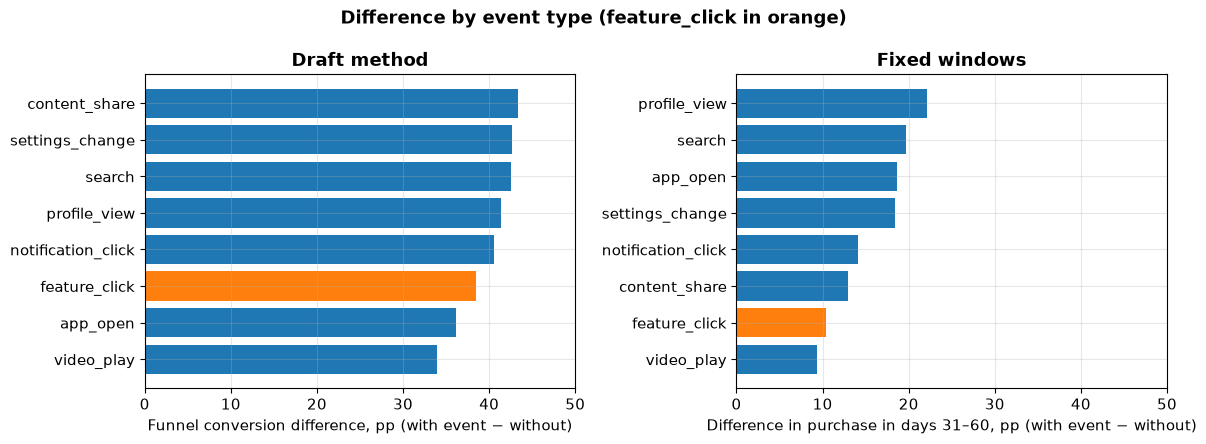

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

panels = [
    (by_event_draft, "Draft method", "Funnel conversion difference, pp"),
    (by_event_fixed, "Fixed windows", "Difference in purchase in days 31–60, pp"),
]
for ax, (data, title, xlabel) in zip(axes, panels):
    data = data.sort_values("difference_pp")
    colors = ["tab:orange" if e == "feature_click" else "tab:blue" for e in data.index]
    ax.barh(data.index, data["difference_pp"], color=colors)
    ax.set_title(title)
    ax.set_xlabel(xlabel + " (with event − without)")
    ax.set_xlim(0, 50)

plt.suptitle("Difference by event type (feature_click in orange)", fontweight="bold")
plt.tight_layout()
plt.show()

With the draft method, every non-funnel event type shows a similar difference: users with the event convert at 54.4–57.3%, users without it at 13.2–20.5%, a difference of 33.9–43.4 percentage points. `feature_click` (38.5 pp) is in the middle of this range.

With fixed windows (the event in the first 30 days, any purchase in days 31–60), the difference is smaller but still present for every event type: users with the event purchase at 70.3–73.7%, users without it at 51.1–60.9%, a difference of 9.4–22.1 percentage points. `feature_click` (10.4 pp) is near the bottom of this range. So the fixed windows remove the part of the difference created by the draft method, but the remaining difference is not specific to the feature either.

### Step 3. Comparison within activity groups

In [13]:
by_activity = pd.read_csv(RESULTS + "feature_cohort_by_activity.csv")
by_activity["difference_pp"] = (by_activity["purchase_feature_pct"] - by_activity["purchase_non_feature_pct"]).round(1)

by_activity

,activity_quartile,min_early_events,max_early_events,users,purchase_pct,feature_users,non_feature_users,purchase_feature_pct,purchase_non_feature_pct,difference_pp
0,1,1,13,243,44.9,110,133,46.4,43.6,2.8
1,2,13,20,242,61.2,166,76,58.4,67.1,-8.7
2,3,20,27,242,81.4,204,38,79.9,89.5,-9.6
3,4,27,46,242,83.9,222,20,83.3,90.0,-6.7


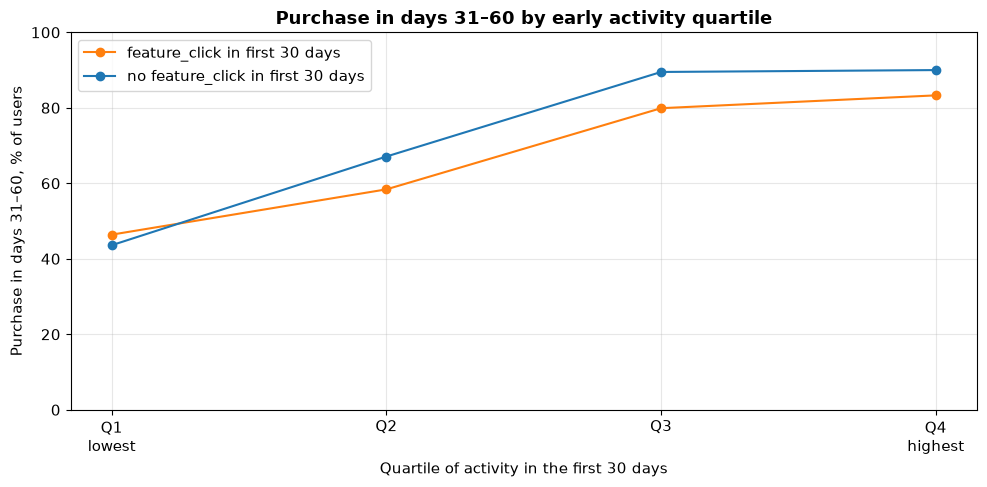

In [14]:
labels = ["Q1\nlowest", "Q2", "Q3", "Q4\nhighest"]

plt.figure(figsize=(10, 5))
plt.plot(labels, by_activity["purchase_feature_pct"], marker="o", color="tab:orange", label="feature_click in first 30 days")
plt.plot(labels, by_activity["purchase_non_feature_pct"], marker="o", color="tab:blue", label="no feature_click in first 30 days")

plt.title("Purchase in days 31–60 by early activity quartile")
plt.xlabel("Quartile of activity in the first 30 days")
plt.ylabel("Purchase in days 31–60, % of users")
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()

Early activity is strongly associated with a later purchase: 44.9% of users in the least active quartile (1–13 events in the first 30 days) purchase in days 31–60, compared with 83.9% in the most active quartile (27–46 events). Feature users are more often in the more active quartiles (110 of 243 users in the first quartile, 222 of 242 in the fourth), so the overall comparison mixes feature usage with early activity.

Within quartiles, the advantage of feature users does not remain: the difference is +2.8, −8.7, −9.6 and −6.7 percentage points. The non-feature groups in the upper quartiles are small (38 and 20 users), so these differences are based on few users and are not interpreted further. Quartile boundaries overlap (13, 20 and 27 events), because users with the same number of events can fall into neighboring quartiles.

### Finding

These data provide no convincing evidence of an advantage specific to feature usage once early activity is taken into account. This is not proof that features have no effect. With the draft method, part of the difference is created by the method itself, and every non-funnel action shows a similar difference. With fixed windows, the difference is smaller but still present for all actions, and within groups of users with similar early activity, the advantage of feature users does not remain.

Early activity is strongly associated with a later purchase in this dataset. Activity is measured before the outcome, but this comparison still does not establish causality: both may depend on how the data were generated, and other factors were not controlled.

## 7. Key Findings

- **Users are active in a very similar way.** Each of the 13 event types is 7.5–7.8% of events, a user has 20 to 100 events (median 58), and every user is active for 67 to 92 days (median 89).
- **Sessions do not look like visits.** The median session lasts 62 days by event timestamps (while the `duration_ms` field of `session_end` gives 0.5–30 minutes), and `session_end` is the last event in only 23.9% of sessions, so a path analysis inside sessions is not possible on this dataset.
- **No convincing evidence of a feature-specific advantage.** With the draft method, feature users convert at 56.0% vs 17.5%, but every non-funnel action shows a similar difference (33.9–43.4 pp). Part of the difference is created by the method: 106 of 274 non-feature users never got past the first visit.
- **Early activity is strongly associated with a later purchase.** With fixed windows, the difference is 9.4–22.1 pp for all actions (10.4 pp for `feature_click`); within quartiles of activity in the first 30 days, the advantage of feature users does not remain, while the share of users with a purchase in days 31–60 grows from 44.9% to 83.9% with early activity.

## 8. Product Interpretation

In a real product, a large conversion difference between feature users and non-feature users would often be taken as a reason to promote the feature. This analysis shows three checks that are useful before drawing such a conclusion:

1. **Check how the cohort is defined.** If the action is counted until a later step of the outcome, users who get further have more time to perform it, and the comparison favors them by construction. Fixed windows from the same starting point avoid this: here, the action in the first 30 days after the first visit and the outcome in days 31–60.
2. **Compare with other actions.** If any action shows a similar difference, the difference is more likely related to overall engagement than to the specific feature.
3. **Compare users with similar activity.** If the difference does not remain within groups of users with similar early activity, the feature is more likely a sign of an active user than a cause of purchases.

In this dataset, all three checks indicate that the difference is not specific to feature usage, although this does not show that features have no effect. Even if a difference remained after these checks, it would show an association; establishing an effect of the feature would require an experiment.

## 9. Next Questions

1. On a dataset with real user journeys and sessions — what paths lead to purchase and to drop-off within a session?
2. Does the time to the first feature use relate to later activity or purchases, and do individual features (`feature_name`) differ?
3. Do behavioral cohorts based on early actions (for example, the first 7 days) differ in retention (`02_retention_cohorts.ipynb`)?
4. How does user activity relate to acquisition cost and LTV by channel (`06_acquisition_monetization.ipynb`)?

## 10. Limitations

- The dataset is synthetic: event types appear with equal frequency, all users are active for about three months, sessions do not look like visits, and event sequences are inconsistent with a purchase journey (`04_funnel.ipynb`, Section 7).
- The draft method uses funnel conversion without a time limit, which depends on how many events a user has; the fixed windows use any purchase in days 31–60. Other windows or outcomes could give different differences.
- Early activity counts all events except `session_end` in the first 30 days, including funnel events; it is one simple measure of activity.
- Feature users are defined by any `feature_click` event, across all 10 `feature_name` values; individual features are not compared.
- Some groups are small (20 and 38 non-feature users in the two most active quartiles), so differences within quartiles are not interpreted.
- The analysis is observational and does not establish causality.

## 11. References

Cohort definitions follow Amplitude's product analytics materials:

- Amplitude — [The Complete Guide to Cohort Analysis](https://amplitude.com/explore/analytics/cohort-analysis)
- Amplitude — [What Is Funnel Analysis? Definition, Examples, and Tools](https://amplitude.com/blog/funnel-analysis)
- Dataset — [adisomani/duckdb_product_analytics_tutorial](https://github.com/adisomani/duckdb_product_analytics_tutorial)